<a href="https://colab.research.google.com/github/MariaMinottaZ/rock-paper-scissors-YOLOv11/blob/main/YOLOV11_Rock_paper_scissors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Cargar dataset

Se buscaron diferentes datasets en roboflow y se escogió uno de (piedra-papel-tijera).

https://universe.roboflow.com/roboflow-58fyf/rock-paper-scissors-sxsw



Ejemplo de imágenes

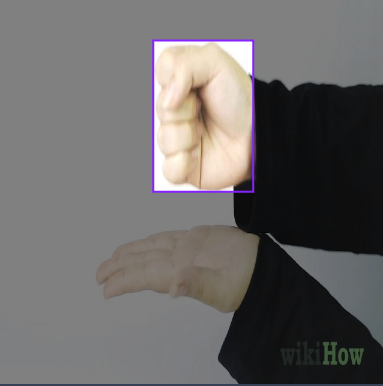

Se descarga el dataset usando la api de roboflow y se mueve a nuestra carpeta de drive

In [ ]:
# Instalar la librería roboflow
!pip install roboflow

# Importar las librerías necesarias
from roboflow import Roboflow
from google.colab import drive
import shutil
import os

# Montar Google Drive
drive.mount('/content/drive')

# Configurar la API de Roboflow y descargar el dataset
rf = Roboflow(api_key="eMUvefxAo5BMXTIRjLKc")
project = rf.workspace("roboflow-58fyf").project("rock-paper-scissors-sxsw")
version = project.version(14)
dataset = version.download("yolov11")

# Ruta destino en Google Drive
destination_folder = '/content/drive/MyDrive/YOLOV11/Dataset'

os.makedirs(destination_folder, exist_ok=True)

# Mover el dataset descargado a la carpeta de destino
shutil.move(dataset.location, destination_folder)

print(f"Dataset movido a: {destination_folder}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.9/80.9 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.7 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to rock-paper-scissors-14 in yolov11:: 100%|██████████| 14682/14682 [00:02<00:00, 6413.35it/s]


Dataset movido a: /content/drive/MyDrive/YOLOV11/Dataset


#Yolo V11 preentrenado

##Creacion y entrenamiento del modelo

Entrenar yolo preentrenado con el dataset de imagenes

In [ ]:
%pip install ultralytics

from ultralytics import YOLO
from google.colab import drive

# Montar Google Drive
drive.mount('/content/drive', force_remount=True)


output_dir = '/content/drive/MyDrive/YOLOV11/Modelo/'

yaml_path = "/content/drive/MyDrive/YOLOV11/Dataset/rock-paper-scissors-14/data.yaml"



model = YOLO("yolo11n.pt")

results = model.train(data=yaml_path, epochs=20, imgsz=640, project=output_dir, name='modelo_piedra_papel_tijera_preentrenado',
    save_period=5,  # Guardar cada 5 épocas
    plots=True,  # Graficar las métricas de entrenamiento
)




Mounted at /content/drive
New https://pypi.org/project/ultralytics/8.3.31 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.30 🚀 Python-3.10.12 torch-2.5.0+cu121 CPU (Intel Xeon 2.20GHz)
engine/trainer: task=detect, mode=train, model=yolo11n.pt, data=/content/drive/MyDrive/YOLOV11/Dataset/rock-paper-scissors-14/data.yaml, epochs=20, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=5, cache=False, device=None, workers=8, project=/content/drive/MyDrive/YOLOV11/Modelo/, name=modelo_piedra_papel_tijera_preentrenado3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_

train: Scanning /content/drive/MyDrive/YOLOV11/Dataset/rock-paper-scissors-14/train/labels.cache... 6455 images, 2516 backgrounds, 0 corrupt: 100%|██████████| 6455/6455 [00:00<?, ?it/s]


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


val: Scanning /content/drive/MyDrive/YOLOV11/Dataset/rock-paper-scissors-14/valid/labels.cache... 576 images, 238 backgrounds, 0 corrupt: 100%|██████████| 576/576 [00:00<?, ?it/s]

partially initialized module 'pandas' has no attribute '_pandas_parser_CAPI' (most likely due to a circular import)
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.001429, momentum=0.9) with parameter groups 81 weight(decay=0.0), 88 weight(decay=0.0005), 87 bias(decay=0.0)


TensorBoard: model graph visualization added ✅
Image sizes 640 train, 640 val
Using 0 dataloader workers
Logging results to /content/drive/MyDrive/YOLOV11/Modelo/modelo_piedra_papel_tijera_preentrenado3
Starting training for 20 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


       1/20         0G      1.277      3.507       1.47         32        640:  62%|██████▏   | 252/404 [58:48<36:10, 14.28s/it]

Épocas del modelo preentrenado

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/20      2.58G      1.291      3.207      1.469          7        640: 100%|██████████| 404/404 [02:49<00:00,  2.38it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:06<00:00,  2.60it/s]
                   all        576        400      0.645      0.412        0.5       0.29

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/20      2.36G      1.403      2.258       1.51          7        640: 100%|██████████| 404/404 [02:41<00:00,  2.50it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:09<00:00,  1.88it/s]                   all        576        400      0.358      0.341      0.286       0.16


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      2.37G      1.401      1.988      1.512          6        640: 100%|██████████| 404/404 [02:43<00:00,  2.47it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:07<00:00,  2.45it/s]                   all        576        400      0.569      0.662       0.66      0.413


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      2.37G      1.379      1.793       1.49          6        640: 100%|██████████| 404/404 [02:42<00:00,  2.48it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:06<00:00,  2.80it/s]                   all        576        400      0.626      0.599      0.643      0.397


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       5/20      2.37G      1.301      1.598       1.43         15        640: 100%|██████████| 404/404 [02:45<00:00,  2.44it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:09<00:00,  1.89it/s]                   all        576        400      0.716      0.689      0.746      0.485


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       6/20      2.37G      1.221      1.434      1.375          7        640: 100%|██████████| 404/404 [02:41<00:00,  2.50it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:06<00:00,  2.86it/s]                   all        576        400      0.774      0.725      0.799      0.565


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       7/20      2.37G      1.179      1.365      1.345          4        640: 100%|██████████| 404/404 [02:49<00:00,  2.38it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:08<00:00,  2.18it/s]                   all        576        400      0.864      0.733      0.857        0.6


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       8/20      2.37G      1.159      1.255      1.334          9        640: 100%|██████████| 404/404 [02:42<00:00,  2.49it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:07<00:00,  2.31it/s]                   all        576        400      0.774      0.742      0.827       0.59


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       9/20      2.37G      1.102      1.166      1.286          6        640: 100%|██████████| 404/404 [02:41<00:00,  2.50it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:07<00:00,  2.30it/s]                   all        576        400       0.86      0.787      0.884      0.623


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      10/20      2.37G      1.074      1.111       1.27          9        640: 100%|██████████| 404/404 [02:50<00:00,  2.36it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:08<00:00,  2.07it/s]                   all        576        400      0.925      0.852      0.923      0.684

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      11/20      2.53G     0.9461     0.7967      1.214          4        640: 100%|██████████| 404/404 [02:36<00:00,  2.58it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:06<00:00,  2.63it/s]                   all        576        400      0.897      0.845      0.907      0.676


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      12/20      2.37G     0.9169     0.7399      1.191          7        640: 100%|██████████| 404/404 [02:39<00:00,  2.53it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:07<00:00,  2.46it/s]                   all        576        400      0.904      0.857       0.91      0.682


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      13/20      2.37G     0.8788     0.6612      1.167          6        640: 100%|██████████| 404/404 [02:35<00:00,  2.61it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:07<00:00,  2.40it/s]                   all        576        400      0.925      0.866      0.934      0.708


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      14/20      2.37G     0.8471     0.6024      1.139          4        640: 100%|██████████| 404/404 [02:41<00:00,  2.51it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:06<00:00,  2.98it/s]                   all        576        400      0.914      0.891      0.938      0.719


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      15/20      2.37G     0.8048     0.5817      1.115          4        640: 100%|██████████| 404/404 [02:42<00:00,  2.49it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:05<00:00,  3.02it/s]                   all        576        400      0.909      0.908       0.93      0.721


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      16/20      2.37G     0.7782     0.5305       1.09          7        640: 100%|██████████| 404/404 [02:43<00:00,  2.48it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:07<00:00,  2.35it/s]                   all        576        400      0.901      0.913      0.944      0.737


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      17/20      2.37G     0.7532      0.503      1.079          5        640: 100%|██████████| 404/404 [02:35<00:00,  2.60it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:06<00:00,  2.62it/s]                   all        576        400      0.914      0.935      0.945       0.75


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      18/20      2.37G     0.7267     0.4736      1.061          4        640: 100%|██████████| 404/404 [02:38<00:00,  2.55it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:06<00:00,  2.67it/s]                   all        576        400      0.951      0.899      0.951      0.761


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      19/20      2.37G     0.6896     0.4382      1.038          2        640: 100%|██████████| 404/404 [02:35<00:00,  2.60it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:05<00:00,  3.14it/s]                   all        576        400      0.937      0.923      0.946      0.761


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      20/20      2.37G     0.6572     0.4093      1.022          4        640: 100%|██████████| 404/404 [02:38<00:00,  2.55it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 18/18 [00:05<00:00,  3.16it/s]                   all        576        400      0.933      0.928      0.952      0.768


                

Se entrenó en otro notebook para poder usar una máquina virtual con GPU y luego se pasó la carpeta de resultados a este proyecto así como los logs de las epocas. https://colab.research.google.com/drive/1cNaCyBEKoFJYf84p0vNA44iUlbWQuuv_#scrollTo=kB4KnUA6KxY5

##Gráficas

Gráfica de la precisión vs las epocas donde podemos observar como el modelo va aumentando la precisión mientras aumentan las epocas

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


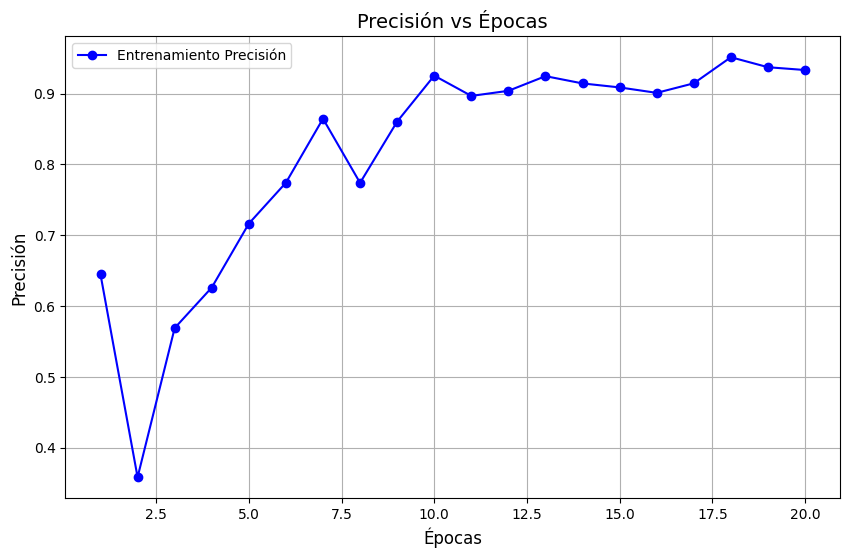

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# Montar Google Drive
drive.mount('/content/drive')


csv_path = "/content/drive/MyDrive/YOLOV11/Modelo/modelo_piedra_papel_tijera_preentrenado/results.csv"

# Cargar el CSV en un DataFrame
df = pd.read_csv(csv_path)

# Extraer las columnas de interés para la precisión en entrenamiento y validación
epochs = df['epoch']
train_precision = df['metrics/precision(B)']

# Crear el gráfico
plt.figure(figsize=(10, 6))

# Graficar la precisión para el entrenamiento y la validación
plt.plot(epochs, train_precision, label="Entrenamiento Precisión", color='blue', marker='o')

# Añadir etiquetas y título
plt.title('Precisión vs Épocas', fontsize=14)
plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Precisión', fontsize=12)

# Añadir una leyenda
plt.legend()

# Mostrar la gráfica
plt.grid(True)
plt.show()


En esta gráfica se puede apreciar el box loss ( la cual mide el error en la predicción de la posición de las cajas delimitadores) del dataset de entrenamiento y de validación enfrentrados

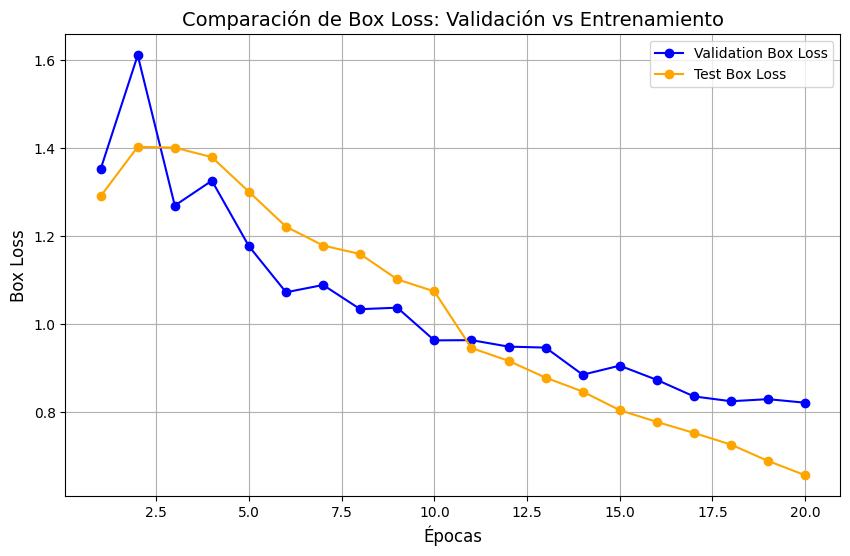

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "/content/drive/MyDrive/YOLOV11/Modelo/modelo_piedra_papel_tijera_preentrenado/results.csv"


df = pd.read_csv(csv_path)


epochs = df['epoch']

# Pérdidas de cajas de validación y prueba

val_box_loss = df['val/box_loss']

train_box_loss = df['train/box_loss']

# Graficar las pérdidas de cajas
plt.figure(figsize=(10, 6))

# Graficar la pérdida de cajas de validación
plt.plot(epochs, val_box_loss, label="Validation Box Loss", color='blue', marker='o')

# Graficar la pérdida de cajas de prueba
plt.plot(epochs, train_box_loss, label="Test Box Loss", color='orange', marker='o')

# Añadir etiquetas y título
plt.title('Comparación de Box Loss: Validación vs Entrenamiento', fontsize=14)
plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Box Loss', fontsize=12)

# Añadir leyenda
plt.legend()

# Mostrar la gráfica
plt.grid(True)
plt.show()

##Deteccion de objetos

In [ ]:
!yolo predict model='/content/drive/MyDrive/YOLOV11/Modelo/modelo_piedra_papel_tijera_preentrenado/weights/best.pt' source='/content/drive/MyDrive/YOLOV11/Imagenes-Videos/imagen.jpg'

Ultralytics 8.3.31 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (Tesla T4, 15102MiB)
YOLO11n summary (fused): 238 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs

image 1/1 /content/drive/MyDrive/YOLOV11/Imagenes-Videos/imagen.jpg: 384x640 1 Rock, 1 Scissors, 55.7ms
Speed: 2.9ms preprocess, 55.7ms inference, 567.3ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/detect/predict2
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [ ]:
!yolo predict model='/content/drive/MyDrive/YOLOV11/Modelo/modelo_piedra_papel_tijera_preentrenado/weights/best.pt' source='/content/drive/MyDrive/YOLOV11/Imagenes-Videos/imagen2.jpg'

Ultralytics 8.3.31 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (Tesla T4, 15102MiB)
YOLO11n summary (fused): 238 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs

image 1/1 /content/drive/MyDrive/YOLOV11/Imagenes-Videos/imagen4.jpg: 448x640 1 Paper, 1 Scissors, 43.0ms
Speed: 4.4ms preprocess, 43.0ms inference, 684.1ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/detect/predict8
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [ ]:
!yolo predict model='/content/drive/MyDrive/YOLOV11/Modelo/modelo_piedra_papel_tijera_preentrenado/weights/best.pt' source='/content/drive/MyDrive/YOLOV11/Imagenes-Videos/imagen3.jpg'

Ultralytics 8.3.31 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (Tesla T4, 15102MiB)
YOLO11n summary (fused): 238 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs

image 1/1 /content/drive/MyDrive/YOLOV11/Imagenes-Videos/imagen3.jpg: 384x640 1 Rock, 1 Scissors, 45.9ms
Speed: 4.0ms preprocess, 45.9ms inference, 687.0ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/detect/predict9
💡 Learn more at https://docs.ultralytics.com/modes/predict


Imagen 1:

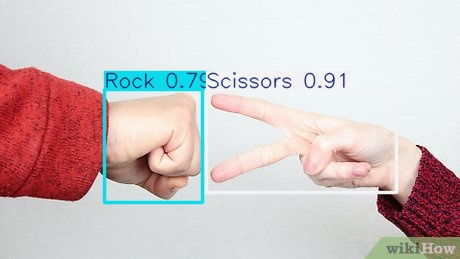

Imagen 2:

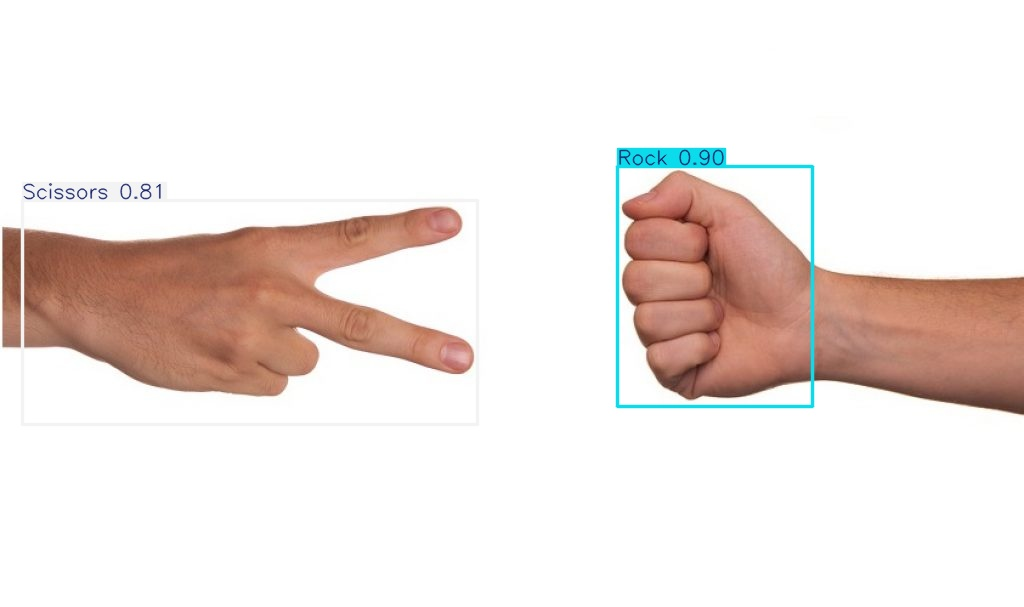

Imagen 3:

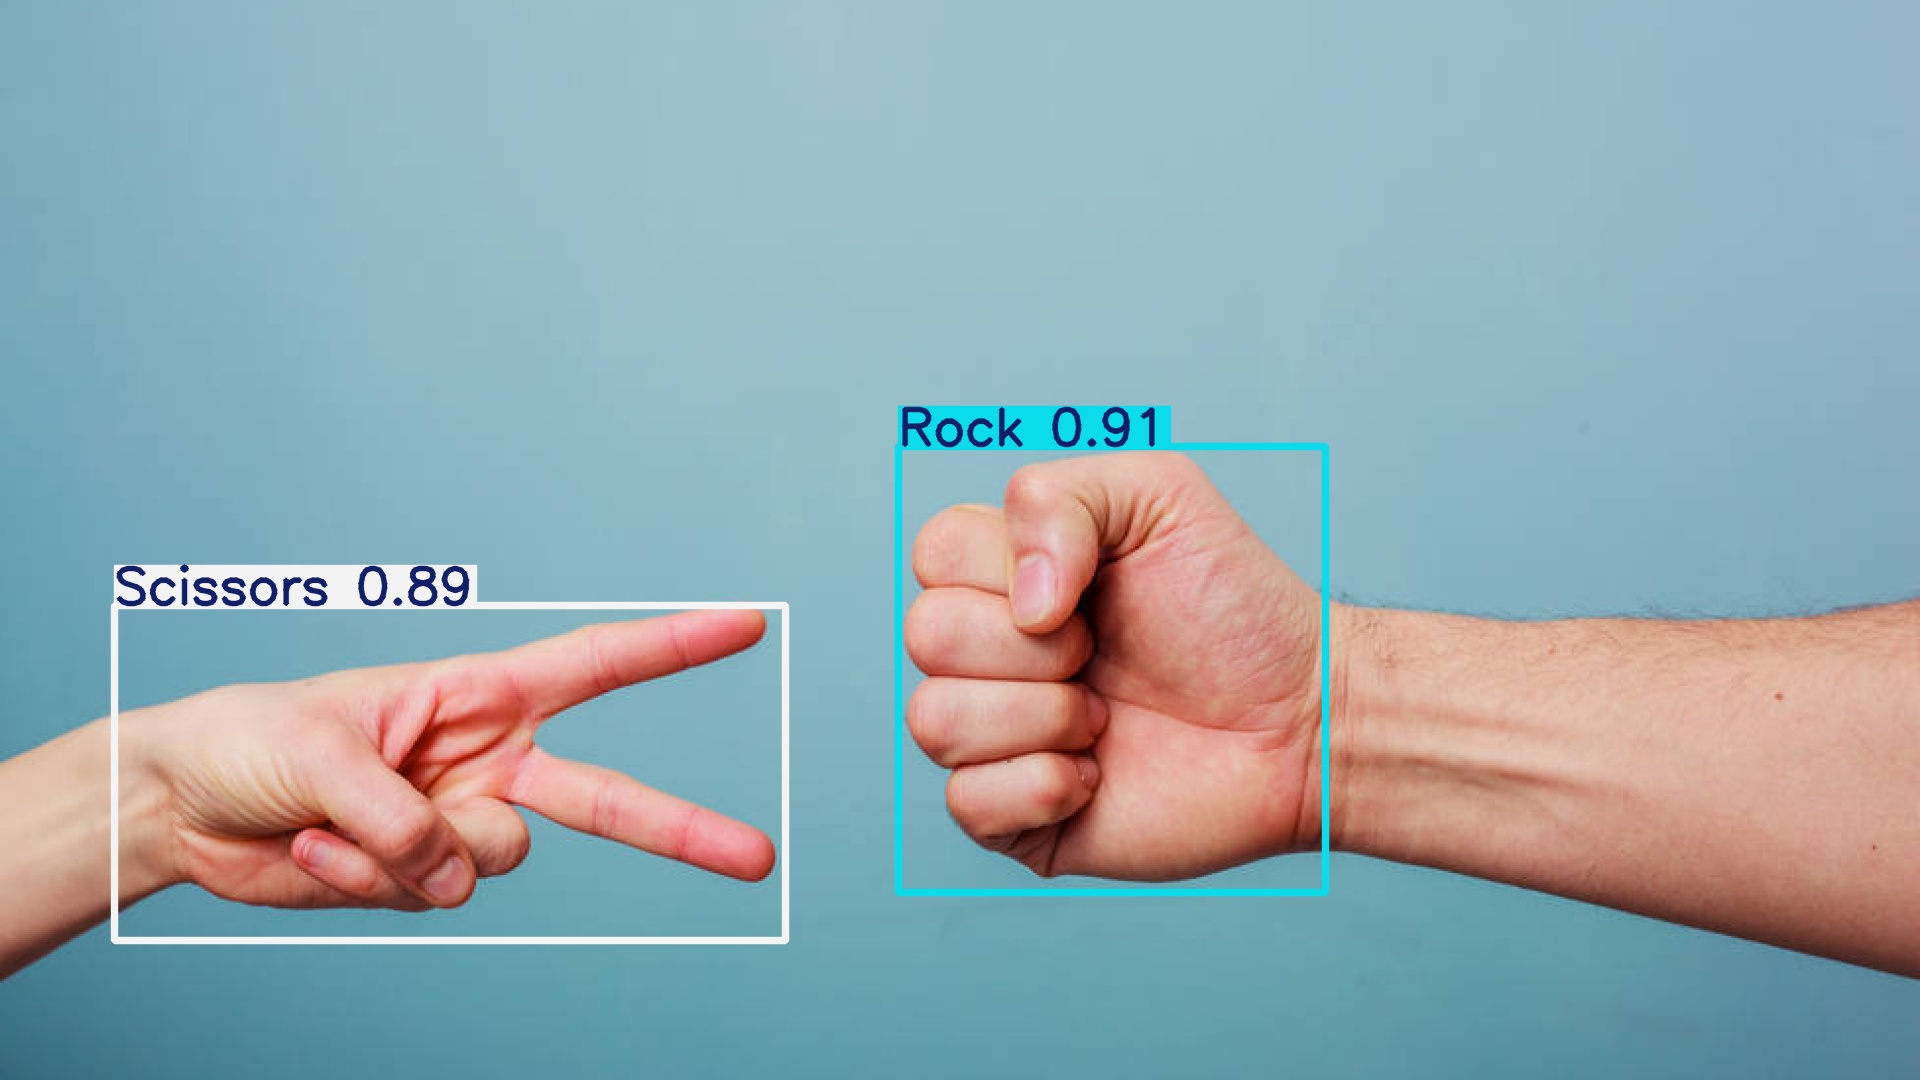

# Conclusiones

Usando el modelo pre-entrenado se logró un mucho mejor resultado con menores épocas (20 epocas totales), el modelo se muestra capaz de reconocer donde van las cajas y que figura se encuentra en ella.
